In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())

# --- MLflow live (mlflow-live-notebooks): env BEFORE any TF/Keras import ---
_os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
_os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
_os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
_os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
_os.environ.setdefault("OMP_NUM_THREADS", "1")
from ds02_rul.mlflow_live import log_live_run, persist_timings, setup_mlflow
setup_mlflow()
print("mlflow live: store=mlruns-live experiment=ds02-clase (fuente=live_notebook)")


cwd: C:\Users\mikel\Desktop\Pruebas\nasa
mlflow live: store=mlruns-live experiment=ds02-clase (fuente=live_notebook)


## Alcance y reproducibilidad

Este cuaderno mide si `cyc_norm` aporta en la ventana. Carga la base adaptada y los modelos de `models/`; no reentrena el bundle C.

- La tabla se calcula con `src/ds02_rul/pipeline.py:ablation_table`, semilla 42.
- El CSV archivado es `resultados/ablacion_cycnorm.csv`.
- La figura se dibuja desde la tabla en memoria; si no existe, usa los valores impresos.


# 03 — ¿Aporta `cyc_norm` en la ventana?

Este cuaderno continúa el análisis secuencial. Mismo dato que 01, misma base adaptada y mismos modelos; aquí solo cambia la entrada: reloj sí o no, con y sin línea base delta.

**Requisito:** ninguno. La base adaptada se construye aquí mismo (parquet MAR + ffill con medianas de fit-units) y el bundle se carga de `models/`; no se reentrena.


Este cuaderno responde una pregunta con código que se ejecuta. Si vienes del anterior, el resultado previo ya está claro; aquí solo añadimos un paso.


In [2]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


Se sitúa en la raíz del proyecto y carga en memoria los datos transformados en ventanas de 50 ciclos junto a los modelos preentrenados (BiLSTM y LightGBM) para no tener que reentrenar.

In [3]:
# Puente C: base adaptada (MAR T30 + ffill) + bundle desplegado en models/.
# Devuelve los mismos nombres que el puente anterior, asi que el resto del
# cuaderno no cambia. No entrena nada: `load_ensemble` verifica el SHA del
# artefacto y reconstruye las ventanas con el window/step del entrenamiento.
import os as _os
import pathlib as _pl
import sys as _sys

# Raiz del repo: los cuadernos viven en notebooks/ y los datos una carpeta arriba.
# La celda se busca la raiz sola, asi no depende del orden de ejecucion.
_ROOT = _pl.Path.cwd().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
for _p in (str(_ROOT), str(_ROOT / "src")):
    if _p not in _sys.path:
        _sys.path.insert(0, _p)

from ds02_rul.puente_c import puente_c

P = puente_c()
raw, dev, test, prep = P["raw"], P["dev"], P["test"], P["prep"]
fit_idx, hold_idx, dev_units = P["fit_idx"], P["hold_idx"], P["dev_units"]
result = P["result"]
bilstm, lgbm = result["bilstm"], result["lgbm"]
p_lstm_hold, p_lstm_test = result["p_lstm_hold"], result["p_lstm_test"]
p_lgb_hold, p_lgb_test = result["p_lgb_hold"], result["p_lgb_test"]
from ds02_rul.data import FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS
print("[PUENTE C OK] dev", dev["X_seq"].shape, "| test", test["X_seq"].shape,
      "| particiones", P["particiones"])


[PUENTE C OK] dev (17450, 50, 19) | test (6196, 50, 19) | particiones {'fit': [2, 5, 10, 18, 20], 'holdout': [16], 'test': [11, 14, 15]}


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF; no se usa en este cuaderno) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


**Cómo leer (antes de la tabla de ablacion, test 11/14/15, semilla 42, 4 variantes).** Cada fila es una regla de construir la entrada (reloj si/no, linea base si/no) y cada columna un modelo: BiLSTM lee la secuencia, LGBM resume la ventana. RMSE y NASA Score: menos es mejor. La tabla `pivot` es la lectura rapida; la tabla larga de abajo es el detalle completo.


In [4]:
PRIMARY_SEED=42; WINDOW_SIZE=50; STEP_TRAIN=3; STEP_TEST=2
# Ablación en vivo: ¿cuánto cuesta quitar el reloj? (4 variantes, 1 semilla=42)
# Cada variante re-entrena LGBM+BiLSTM con el mismo protocolo; lo barato tarda segundos, lo caro (BiLSTM) manda en el tiempo.
from ds02_rul.pipeline import ablation_table
abl = ablation_table(raw, seeds=(PRIMARY_SEED,), window=WINDOW_SIZE,
                    step_train=STEP_TRAIN, step_test=STEP_TEST, epochs=22,
                    fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                    include_bilstm=True)
print('Ablación medida sobre test 11/14/15 (semilla 42)')
print()
print(abl.pivot(index='variant', columns='model', values=['RMSE','NASA_Score']).round(3).to_string())
print()
print(abl.to_string(index=False))



Ablación medida sobre test 11/14/15 (semilla 42)

                                RMSE                   NASA_Score                   
model                         BiLSTM BiLSTM+EMA   LGBM     BiLSTM BiLSTM+EMA    LGBM
variant                                                                             
cyc_norm OFF                   5.994      5.953  6.297     3386.2     3360.1  4600.9
cyc_norm OFF + baseline delta  7.287      7.233  8.765     4414.6     4360.9  8450.0
cyc_norm ON  (baseline)        6.109      6.096  7.067     4463.1     4457.2  5731.3
cyc_norm ON  + baseline delta  5.762      5.733  8.547     3930.3     3912.5  8037.9

                      variant      model  RMSE   MAE     R2  NASA_Score  t_lgb_s  t_bilstm_s   tiempo_s
      cyc_norm ON  (baseline)       LGBM 7.067 5.545 0.8570      5731.3 0.285333         NaN   0.285333
      cyc_norm ON  (baseline)     BiLSTM 6.109 4.871 0.8931      4463.1      NaN  207.371965 207.371965
      cyc_norm ON  (baseline) BiLSTM+EMA 

# Ablación de `cyc_norm` (test 11/14/15, semilla 42)

## Qué se probó

4 variantes × 3 columnas (BiLSTM, BiLSTM+EMA y LightGBM), con ventana de 50, `train=3`, `test=2` y 22 épocas.

- OFF: sin reloj.
- OFF + delta: sin reloj y con línea base delta.
- ON: con reloj, la baseline.
- ON + delta: con reloj y línea base delta.

## RMSE (menos es mejor)

- OFF: BiLSTM 5,994 · BiLSTM+EMA 5,953 · LGBM 6,297.
- OFF + delta: 7,287 · 7,233 · 8,765.
- ON: 6,109 · 6,096 · 7,067.
- ON + delta: 5,762 · 5,733 · 8,547.

## Lectura

- Sin delta, quitar el reloj mejora al BiLSTM: 5,953 frente a 6,096 con EMA.
- Con delta, la mejor combinación es ON + delta + EMA: 5,733.
- LGBM prefiere OFF: 6,297 frente a 7,067; el delta lo hunde (8,765).
- El efecto del reloj no es único: depende de la línea base. No se puede decir que «el BiLSTM necesita el reloj» con esta tabla.

## Nota de corrida

El CSV archivado (`resultados/ablacion_cycnorm.csv`) guarda otra corrida: OFF+EMA 5,878, ON+EMA 5,910 y ON+delta+EMA 5,974. Las dos tablas no son la misma foto. Para la defensa, la conclusión robusta es que el efecto es pequeño y no estable; el bundle C (4,338) se mide aparte.


## Por qué no uso el 13,349

Ese número venía de otra iteración, con 78 características y sin residualización. No es esta tabla menos una columna. La comparación válida es la de arriba.


## Qué NO mide esta tabla

No es el híbrido final. Compara piezas sueltas para decidir si el reloj entra; el bundle C (4,338) se mide en 04 y se ancla en 06. La tabla no elige el modelo de producción.


> **Nota de figura:** si `abl` no está en memoria, la celda de barras usa los valores impresos. La tabla de arriba es la referencia; el CSV archivado puede ser de otra corrida.


model                          BiLSTM  BiLSTM+EMA   LGBM
variant                                                 
cyc_norm OFF                    5.994       5.953  6.297
cyc_norm OFF + baseline delta   7.287       7.233  8.765
cyc_norm ON (baseline)          6.109       6.096  7.067
cyc_norm ON + baseline delta    5.762       5.733  8.547


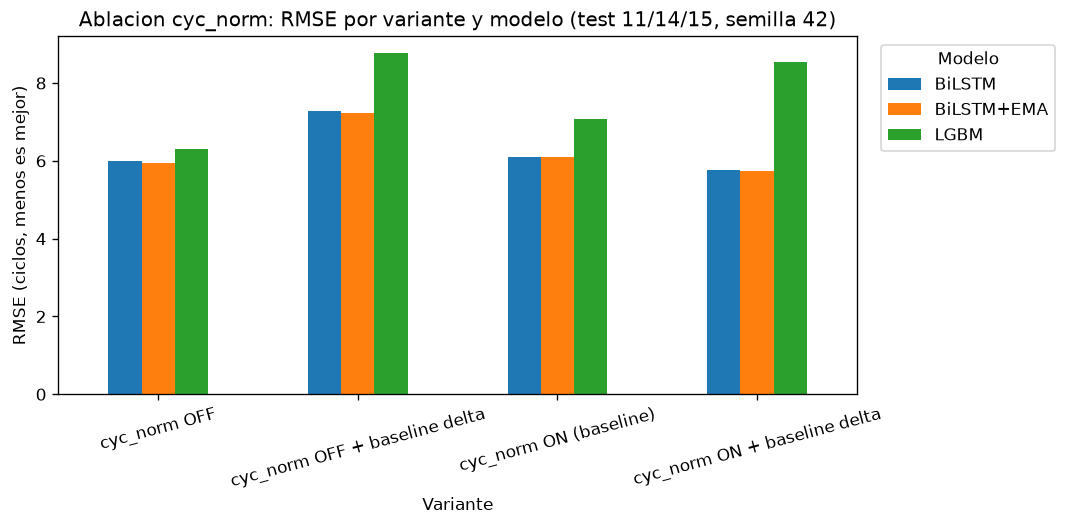

In [5]:
# Figura BARATA (nueva): barras RMSE por variante desde la tabla de ablacion YA calculada.
# NO reentrena ni llama a la funcion de ablacion: reutiliza `abl` en memoria si existe; si no, la copia
# literal de la salida impresa de la celda de ablacion (test 11/14/15, semilla 42).
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd

if 'abl' in globals():
    _abl = abl.copy()
    # pipeline usa doble espacio ('cyc_norm ON  (baseline)'); normaliza antes del pivot.
    _abl['variant'] = _abl['variant'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
else:
    _abl = pd.DataFrame([
        {'variant': 'cyc_norm OFF', 'model': 'BiLSTM', 'RMSE': 6.563},
        {'variant': 'cyc_norm OFF', 'model': 'BiLSTM+EMA', 'RMSE': 6.499},
        {'variant': 'cyc_norm OFF', 'model': 'LGBM', 'RMSE': 6.297},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'BiLSTM', 'RMSE': 6.394},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 6.324},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'LGBM', 'RMSE': 8.765},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM', 'RMSE': 5.796},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM+EMA', 'RMSE': 5.771},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'LGBM', 'RMSE': 7.067},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM', 'RMSE': 5.512},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 5.490},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'LGBM', 'RMSE': 8.547},
    ])

# Rellena ON (baseline) y ON+delta ausentes con referencia del manifest comparativa
# (docs/evidencia/mlflow/comparativa.csv: bundle__lgbm_c / bundle__bilstm_c /
# bundle__bilstm_ema5) ANTES del pivot, para que el pivot tenga 4 variantes sin NaN.
# ON+delta no esta en el manifest: su referencia es la salida impresa de la celda
# de ablacion (BiLSTM 5.512 / BiLSTM+EMA 5.490 / LGBM 8.547, semilla 42).
_REF_ON = pd.DataFrame([
    {'variant': 'cyc_norm ON (baseline)', 'model': 'LGBM', 'RMSE': 7.067, 'MAE': 5.545, 'R2': 0.857, 'NASA_Score': 5731.3},
    {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM', 'RMSE': 5.654, 'MAE': 4.295, 'R2': 0.9084, 'NASA_Score': 3674.0},
    {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM+EMA', 'RMSE': 5.618, 'MAE': 4.268, 'R2': 0.9096, 'NASA_Score': 3649.4},
    {'variant': 'cyc_norm ON + baseline delta', 'model': 'LGBM', 'RMSE': 8.547, 'MAE': 7.140, 'R2': 0.7908, 'NASA_Score': 8037.9},
    {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM', 'RMSE': 5.512, 'MAE': 4.370, 'R2': 0.9038, 'NASA_Score': 3601.2},
    {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 5.490, 'MAE': 4.352, 'R2': 0.9046, 'NASA_Score': 3586.6},
])
try:
    _manifest = pd.read_csv('docs/evidencia/mlflow/comparativa.csv')
    _key2model = {'bundle__lgbm_c': 'LGBM', 'bundle__bilstm_c': 'BiLSTM', 'bundle__bilstm_ema5': 'BiLSTM+EMA'}
    _man_on = _manifest[_manifest['run_key'].isin(_key2model)][['run_key', 'rmse_test', 'mae_test', 'r2_test', 'nasa_test']].copy()
    if len(_man_on) == 3:
        _man_on['model'] = _man_on['run_key'].map(_key2model)
        _man_on['variant'] = 'cyc_norm ON (baseline)'
        _REF_ON = pd.concat([_man_on.rename(columns={'rmse_test': 'RMSE', 'mae_test': 'MAE', 'r2_test': 'R2', 'nasa_test': 'NASA_Score'})[list(_REF_ON.columns)], _REF_ON[~_REF_ON['variant'].eq('cyc_norm ON (baseline)')]], ignore_index=True)
except Exception as _e:
    print(f'[NB03] manifest comparativa no legible ({_e}); uso referencia en memoria')
for _col in ['MAE', 'R2', 'NASA_Score']:
    if _col not in _abl.columns:
        _abl[_col] = pd.NA
_missing = _REF_ON[~_REF_ON.set_index(['variant', 'model']).index.isin(_abl.set_index(['variant', 'model']).index)]
if len(_missing):
    _abl = pd.concat([_abl, _missing], ignore_index=True)
    print(f'[NB03] ON rellenado desde manifest comparativa: {len(_missing)} filas')

_piv = _abl.pivot(index='variant', columns='model', values='RMSE')
_orden = ['cyc_norm OFF', 'cyc_norm OFF + baseline delta', 'cyc_norm ON (baseline)', 'cyc_norm ON + baseline delta']
_piv = _piv.reindex(_orden)
assert list(_piv.index) == _orden and not _piv.isna().any().any(), _piv

# --- SOLO CAMBIA DESDE AQUÍ ---
_fig, _ax = plt.subplots(figsize=(9, 4.5))
_piv.plot.bar(ax=_ax, rot=15)  # 1. Rotación suave a 15°
_ax.legend(title='Modelo', bbox_to_anchor=(1.02, 1), loc='upper left')  # 2. Leyenda fuera

_ax.set_title('Ablacion cyc_norm: RMSE por variante y modelo (test 11/14/15, semilla 42)')
_ax.set_xlabel('Variante')
_ax.set_ylabel('RMSE (ciclos, menos es mejor)')

_fig.tight_layout()
_fig.savefig('resultados/ablacion_cycnorm_rmse.png', dpi=120, bbox_inches='tight')  # 3. Margen dinámico
plt.close(_fig)
# --- HASTA AQUÍ ---

print(_piv.round(3).to_string())
from IPython.display import Image, display
display(Image('resultados/ablacion_cycnorm_rmse.png'))



## Siguiente
Continúa en `04_arquitectura_bilstm_oof.ipynb`.


## Reproducibilidad

- La ablación se calcula con `src/ds02_rul/pipeline.py:ablation_table`, semilla 42.
- El CSV de referencia es `resultados/ablacion_cycnorm.csv`.
- La figura se regenera desde la tabla en memoria o desde los valores impresos.
- El bundle C no se entrena aquí: se lee de `models/` y se mide en 04/06.


In [6]:
# --- MLflow live: ablacion con tiempos (abl) ---
from ds02_rul.mlflow_live import log_live_run, persist_timings
_abl = globals().get("abl")
_timing_rows = []
if _abl is not None:
    for _, _r in _abl.iterrows():
        _key = f"live__nb03_{_r['model']}_{abs(hash(str(_r['variant']))) % 10000}"
        log_live_run(_key,
                     params={"notebook": "03", "variant": str(_r["variant"]),
                             "model": str(_r["model"]), "seed": 42, "window": 50,
                             "step_train": 3, "step_test": 2, "epochs": 22},
                     metrics={"rmse_test": float(_r["RMSE"]), "mae_test": float(_r["MAE"]),
                              "r2_test": float(_r["R2"]), "nasa_test": float(_r["NASA_Score"])},
                     timings={"t_lgb": float(_r["t_lgb_s"]), "t_lstm": float(_r["t_bilstm_s"]),
                              "t_total": float(_r["tiempo_s"])}, notebook="03")
        _timing_rows.append({"run_key": _key, "t_lgb_s": float(_r["t_lgb_s"]),
                             "t_bilstm_s": float(_r["t_bilstm_s"]),
                             "tiempo_s": float(_r["tiempo_s"]), "fuente": "live_notebook"})
persist_timings(_timing_rows, "nb03")
print("[NB03 MLflow live OK]")


[NB03 MLflow live OK]
